<div dir="rtl" style="text-align: right; font-family: Tahoma, Vazirmatn, sans-serif; line-height: 1.8;">

<h1>تکلیف : تفسیرپذیری مدل‌های زبانی بزرگ (LLM Interpretability) با BERT</h1>

<h2>مصورسازی بازنمایی‌ها (Representations) قبل و بعد از ریزتنظیم (Fine-tuning)</h2>

<hr>

<h2>مجموعه‌داده (Dataset)</h2>

<p>
در این تکلیف از مجموعه‌داده
<b>SST-2 (Stanford Sentiment Treebank – Binary)</b>
از بنچمارک
<b>GLUE (General Language Understanding Evaluation)</b>
استفاده می‌کنیم.
</p>

<ul>
  <li>حدود <b>67,000</b> جمله برای آموزش (<b>Training</b>)</li>
  <li>حدود <b>870</b> جمله برای اعتبارسنجی (<b>Validation</b>)</li>
  <li>برچسب‌ها (<b>Labels</b>):
    <ul>
      <li><b>0 = منفی (Negative)</b></li>
      <li><b>1 = مثبت (Positive)</b></li>
    </ul>
  </li>
  <li>این مجموعه‌داده مستقیماً از طریق کتابخانه
      <b>🤗 Datasets</b>
      در دسترس است.
  </li>
</ul>

<hr>

<h2>مدل (Model)</h2>

<p>
<b>bert-base-uncased</b>
</p>

<ul>
  <li>دارای <b>12</b> لایه ترنسفورمر (<b>Transformer Layers</b>)</li>
  <li>ابعاد حالت پنهان (<b>Hidden Dimension</b>) برابر با <b>768</b></li>
  <li>حدود <b>110 میلیون</b> پارامتر (<b>Parameters</b>)</li>
</ul>

<hr>

</div>

## 0  Install & Import

In [ ]:
# Run once – restart runtime afterwards if prompted
#!pip install -q transformers datasets umap-learn bertviz matplotlib seaborn scikit-learn torch torchvision

In [90]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

from transformers import BertModel, BertTokenizer, BertForSequenceClassification, get_linear_schedule_with_warmup

from datasets import load_dataset, load_from_disk

import torchvision
import umap
import bertviz

---
## 1  Load the SST-2 Dataset

In [2]:
# Loads the dataset and prepares the training and validation subsets
#dataset = load_dataset("stanfordnlp/sst2")
#dataset.save_to_disk("./saved_sst2_dataset")
dataset = load_from_disk("./saved_sst2_dataset")

# We work with a small subset so the homework runs fast
N_TRAIN = 2000   # sentences for fine-tuning
N_VAL   = 500    # sentences for validation and visualization

train_dataset = dataset['train'].select(range(N_TRAIN))
val_dataset = dataset['validation'].select(range(N_VAL))

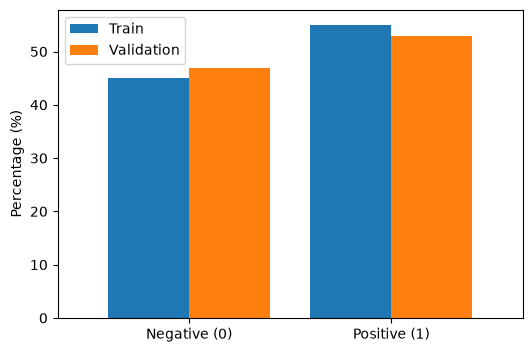

In [16]:
# Class distribution
train_dist = pd.Series(train_dataset['label']).value_counts(normalize=True).sort_index() * 100
val_dist = pd.Series(val_dataset['label']).value_counts(normalize=True).sort_index() * 100

df_dist = pd.DataFrame({'Train': train_dist, 'Validation': val_dist})

df_dist.index = ['Negative (0)', 'Positive (1)']

df_dist.plot(kind='bar', figsize=(6, 4), width=0.8, rot=0)
plt.ylabel('Percentage (%)')
plt.show()

---
## 2  Tokenization & DataLoaders

In [17]:
tokenizer = BertTokenizer.from_pretrained("./saved_bert_tokenizer")

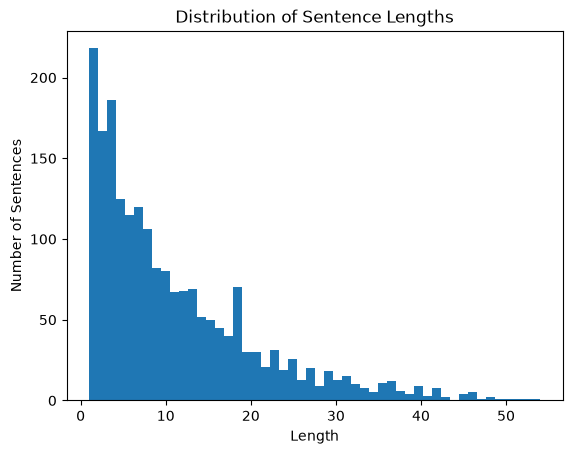

In [ ]:
# to choose the maximum length of sentences
lengths = [len(tokenizer.tokenize(text)) for text in train_dataset['sentence']]

plt.hist(lengths, bins=50)
plt.title('Distribution of Sentence Lengths')
plt.xlabel('Length')
plt.ylabel('Number of Sentences')
plt.show()

In [41]:
# Tokenization and DataLoader preparation
#tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
#tokenizer.save_pretrained("./saved_bert_tokenizer")
tokenizer = BertTokenizer.from_pretrained("./saved_bert_tokenizer")

def tokenize_data(data):
    return tokenizer(list(data['sentence']), padding='max_length', truncation=True, max_length=128, return_tensors='pt')

train_encodings = tokenize_data(train_dataset)
val_encodings = tokenize_data(val_dataset)

train_labels_tensor = torch.tensor(train_dataset['label'])
val_labels_tensor = torch.tensor(val_dataset['label'])

train_data = TensorDataset(train_encodings['input_ids'], train_encodings['attention_mask'], train_labels_tensor)
val_data = TensorDataset(val_encodings['input_ids'], val_encodings['attention_mask'], val_labels_tensor)

BATCH_SIZE = 32

train_dataloader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)
val_dataloader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False)

---
## 3  Helper: Extract [CLS] Representations

The `[CLS]` token sits at position 0 of every BERT output.
It is designed to aggregate sentence-level information and is what the classification head reads.
We collect it from **every layer** (0 = embedding, 1-12 = transformer layers).

In [42]:
# Helper function to extract [CLS] vectors from each layer of BERT for all examples in the dataloader
@torch.no_grad()
def extract_cls_representations(model, dataloader, device):
    model.eval()
    model.to(device)

    all_layers_cls = {i: [] for i in range(13)} 
    all_labels = []
    
    for batch in dataloader:
        input_ids = batch[0].to(device)
        attention_mask = batch[1].to(device)
        labels = batch[2].cpu().tolist()
        
        outputs = model(input_ids, attention_mask=attention_mask, output_hidden_states=True)
        
        hidden_states = outputs.hidden_states 
        
        for i, layer_hidden_state in enumerate(hidden_states):
            cls_state = layer_hidden_state[:, 0, :].cpu()
            all_layers_cls[i].append(cls_state)
            
        all_labels.extend(labels)
        
    for i in range(13):
        all_layers_cls[i] = torch.cat(all_layers_cls[i], dim=0)
        
    return all_layers_cls, torch.tensor(all_labels)


---
## 4  Part A — Pretrained BERT (Before Fine-tuning)
### 4.1  Load pretrained BERT & extract representations

In [43]:
# Load the pretrained BERT model and extract the [CLS] vectors for the validation set
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

#model = BertModel.from_pretrained('bert-base-uncased', output_hidden_states=True)
#model.save_pretrained("./saved_bert_model")
model = BertModel.from_pretrained("./saved_bert_model", output_hidden_states=True)
model.to(device)

val_cls_repr, val_labels = extract_cls_representations(model, val_dataloader, device)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

### 4.2  PCA Visualisation — all 12 transformer layers

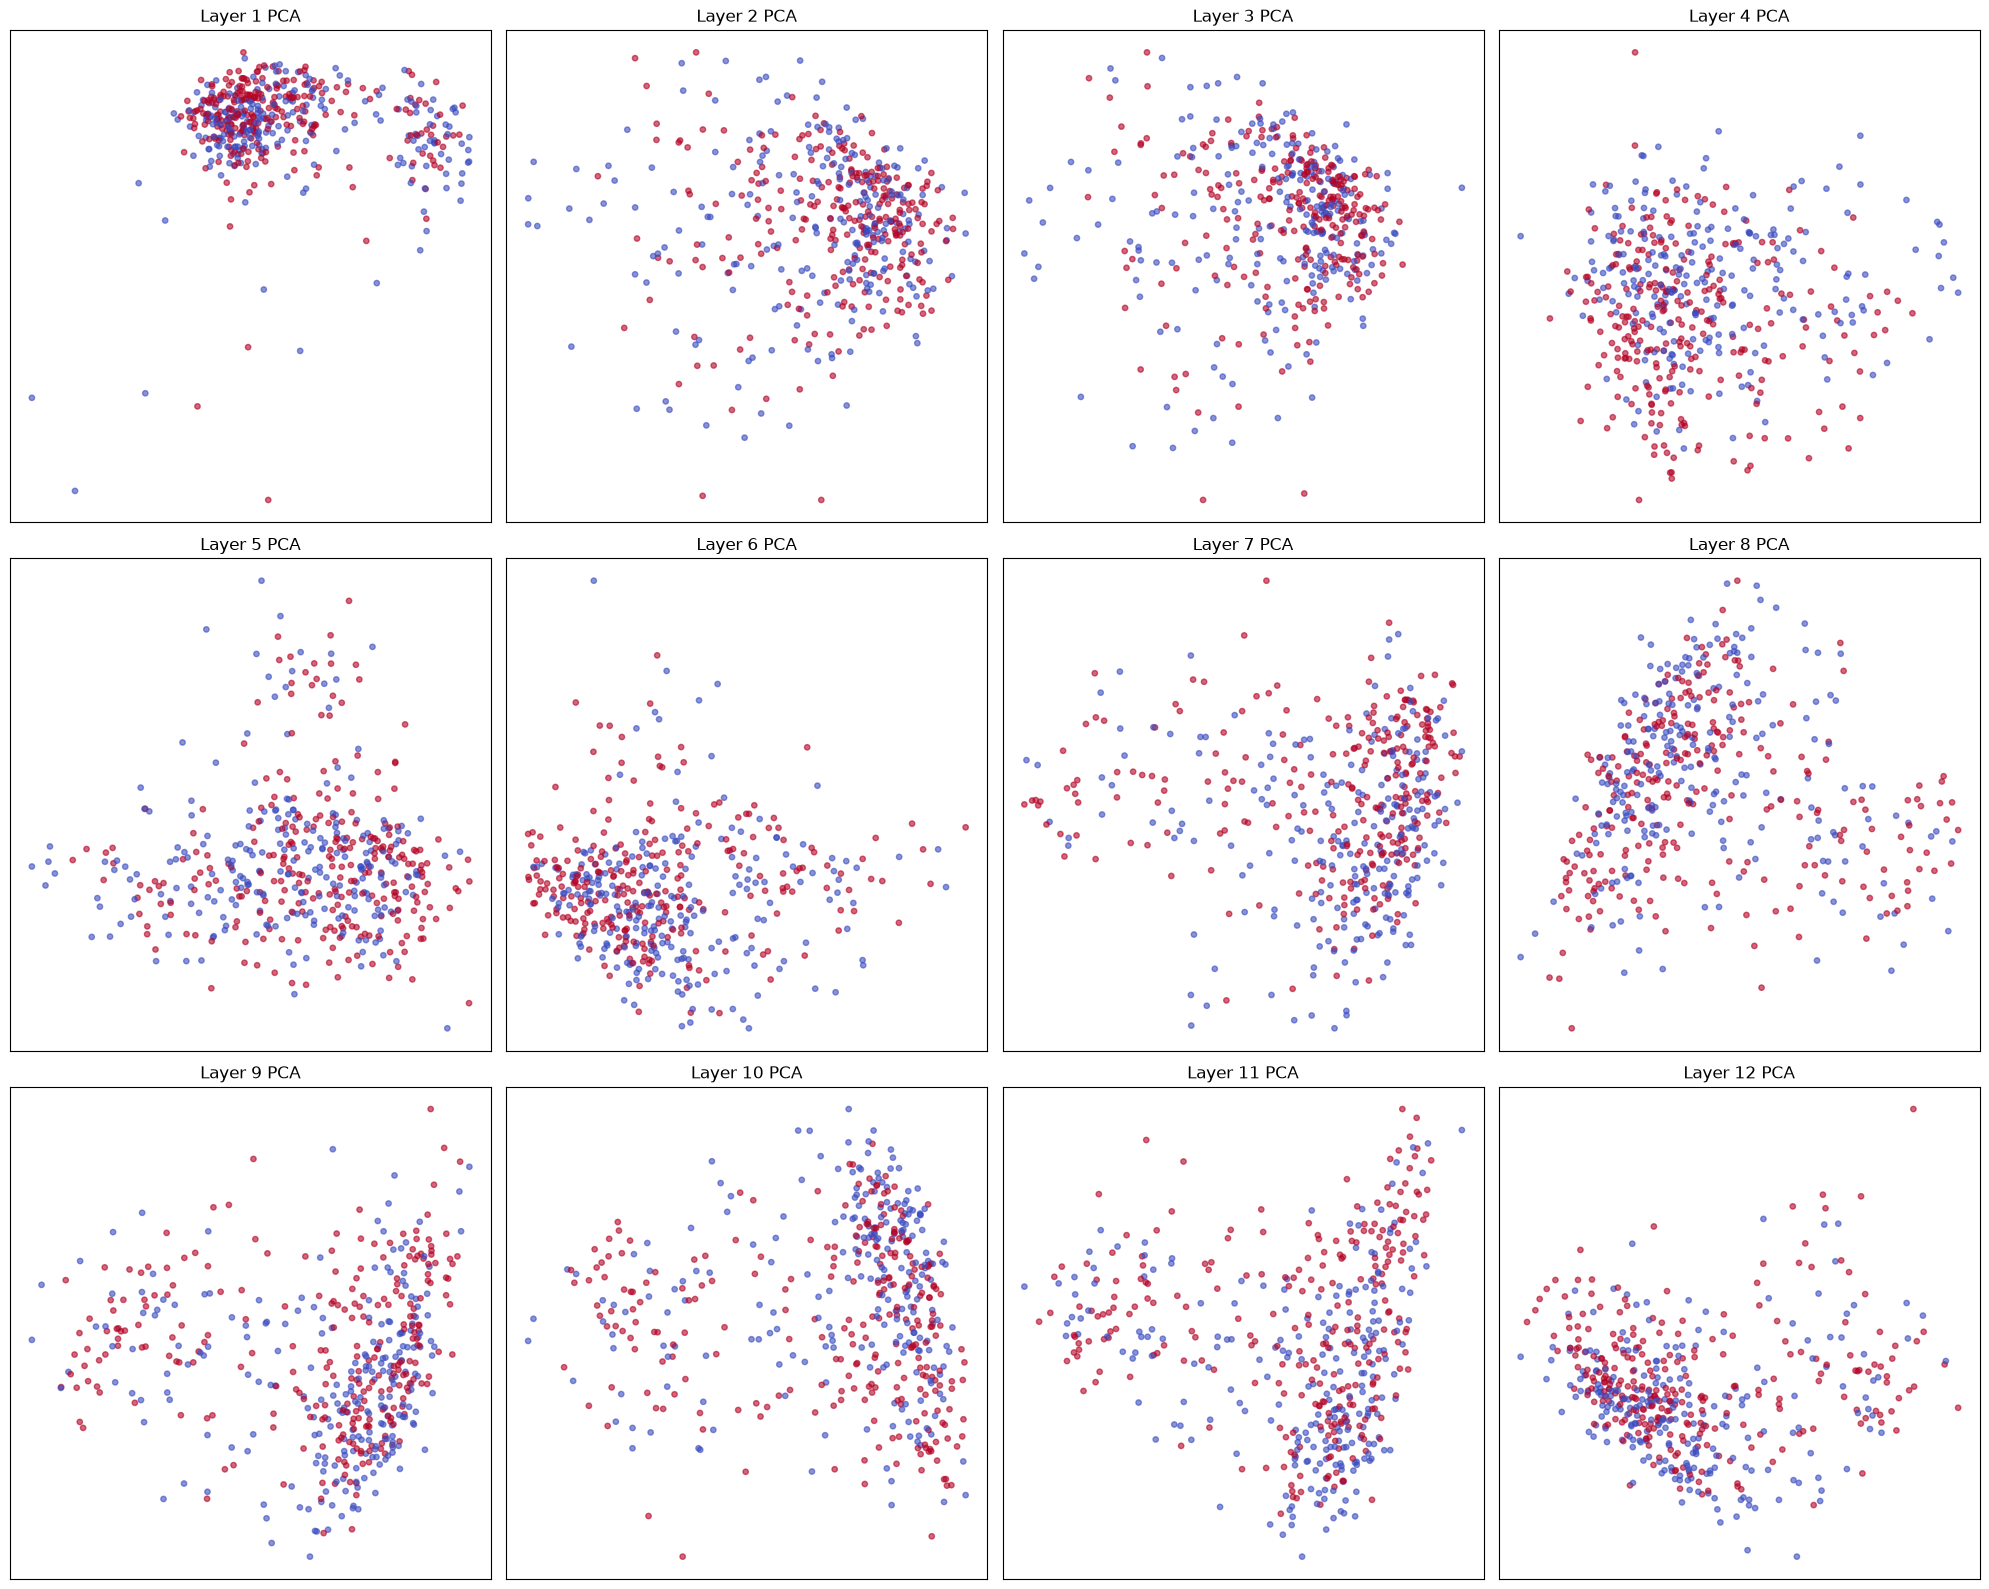

In [ ]:
# Visualize the PCA projections of the [CLS] vectors for all layers in a grid format

pca_layers = list(range(1, 13))

fig, axes = plt.subplots(3, 4, figsize=(20, 16))
axes = axes.flatten()

for idx, layer in enumerate(pca_layers):
    pca = PCA(n_components=2)
    
    X = val_cls_repr[layer].numpy()
    y = val_labels.numpy()
    
    X_pca = pca.fit_transform(X)
    
    ax = axes[idx]
    scatter = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='coolwarm', alpha=0.6, s=15)
    ax.set_title(f'Layer {layer} PCA')
    ax.set_xticks([])
    ax.set_yticks([])

for i in range(len(pca_layers), len(axes)):
    axes[i].axis('off')

plt.tight_layout()
plt.show()


### 4.3  UMAP — deep layers only

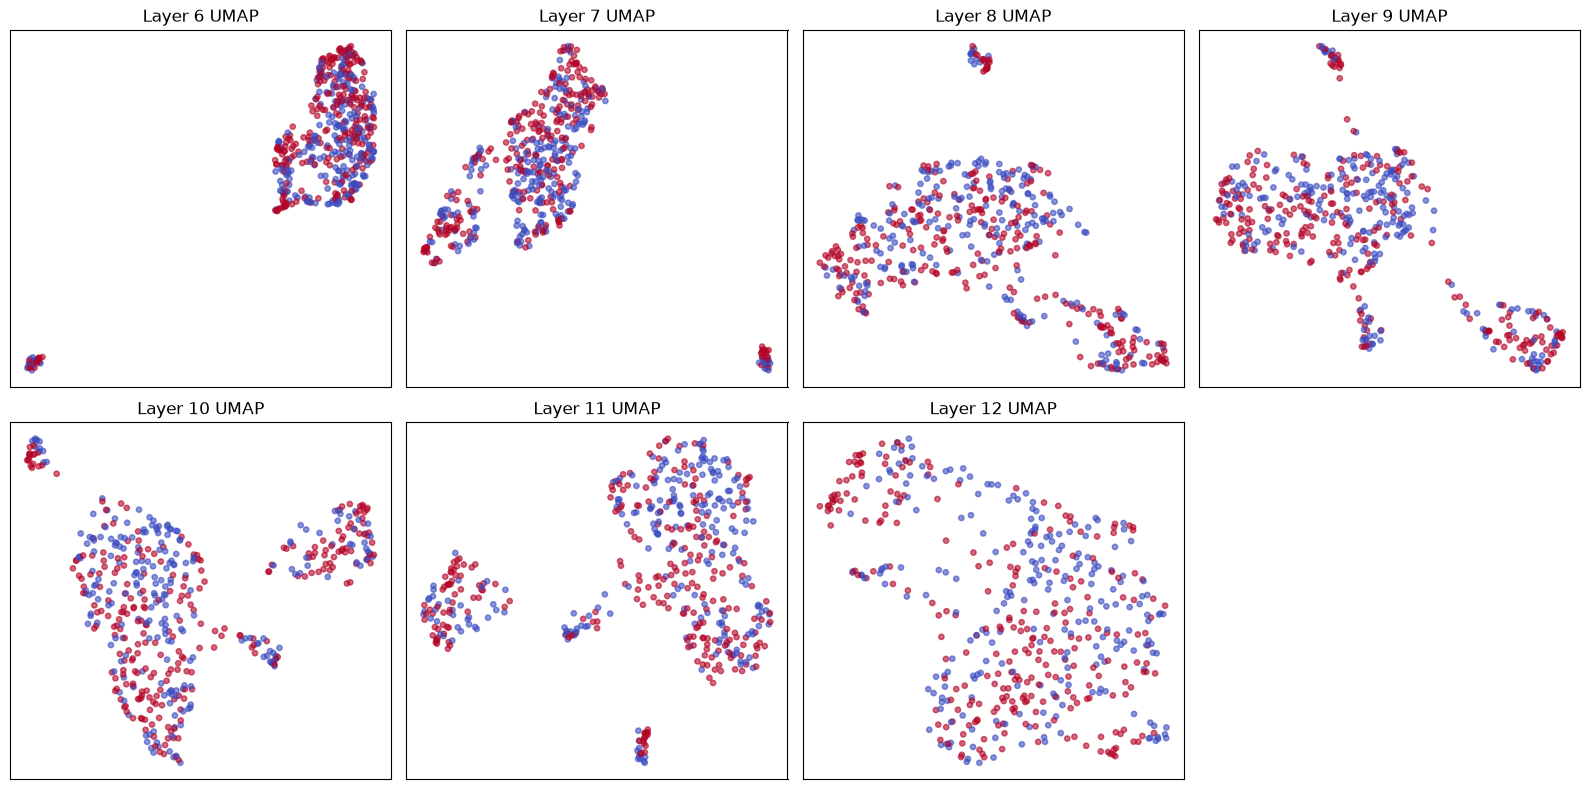

In [52]:
# Visualize the UMAP projections of the [CLS] vectors for selected layers (6, 12) in a grid format

umap_layers = list(range(6, 13)) 

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for idx, layer in enumerate(umap_layers):
    reducer = umap.UMAP(n_components=2, random_state=42)
    
    X = val_cls_repr[layer].numpy()
    y = val_labels.numpy()
    
    X_umap = reducer.fit_transform(X)
    
    ax = axes[idx]
    ax.scatter(X_umap[:, 0], X_umap[:, 1], c=y, cmap='coolwarm', alpha=0.6, s=15)
    ax.set_title(f'Layer {layer} UMAP')
    ax.set_xticks([])
    ax.set_yticks([])

axes[-1].axis('off')

plt.tight_layout()
plt.show()


### 4.4  Layer-wise linear separability (Logistic Probe)
Train a simple logistic regression on each layer's [CLS] vectors.
If accuracy is high, the layer already encodes sentiment linearly.

In [53]:
# Probing classifier: train a logistic regression classifier on the [CLS] vectors from each layer and evaluate using 5-fold cross-validation

probe_scores = {}

for layer in range(13):
    X = val_cls_repr[layer].numpy()
    y = val_labels.numpy()
    
    clf = LogisticRegression(max_iter=1000, random_state=42)
    
    scores = cross_val_score(clf, X, y, cv=5, scoring='accuracy')
    probe_scores[layer] = scores.mean()
    
    print(f"Layer {layer:2d} | Mean Accuracy: {probe_scores[layer]:.4f}")


Layer  0 | Mean Accuracy: 0.5300
Layer  1 | Mean Accuracy: 0.6480
Layer  2 | Mean Accuracy: 0.6640
Layer  3 | Mean Accuracy: 0.6780
Layer  4 | Mean Accuracy: 0.7260
Layer  5 | Mean Accuracy: 0.7400
Layer  6 | Mean Accuracy: 0.7680
Layer  7 | Mean Accuracy: 0.7640
Layer  8 | Mean Accuracy: 0.7780
Layer  9 | Mean Accuracy: 0.7980
Layer 10 | Mean Accuracy: 0.8360
Layer 11 | Mean Accuracy: 0.8480
Layer 12 | Mean Accuracy: 0.8280


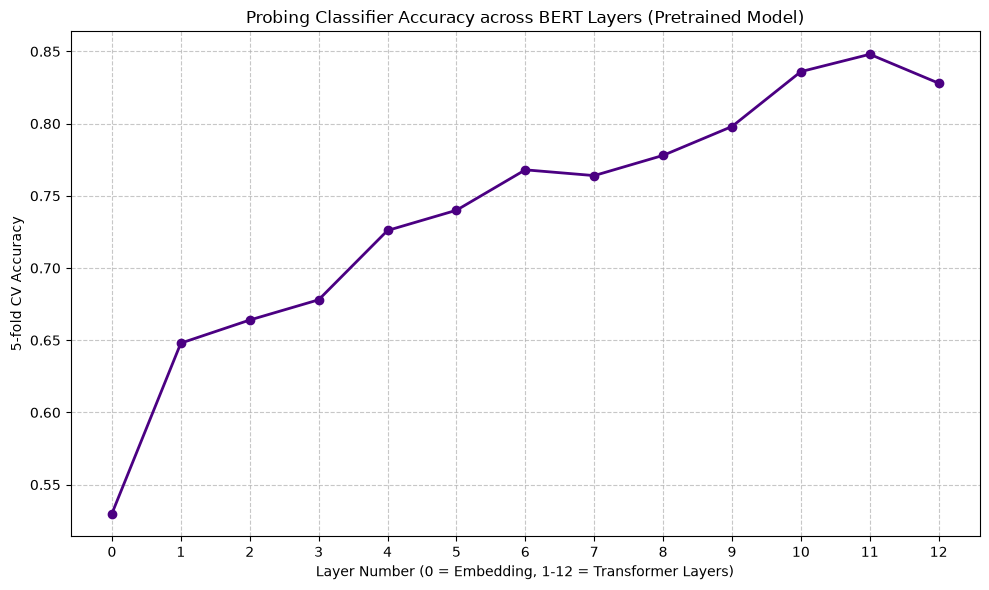

In [54]:
# Visualize the probe scores across layers

layers = list(probe_scores.keys())
scores = list(probe_scores.values())

plt.figure(figsize=(10, 6))
plt.plot(layers, scores, marker='o', linestyle='-', color='indigo', linewidth=2)
plt.title('Probing Classifier Accuracy across BERT Layers (Pretrained Model)')
plt.xlabel('Layer Number ($0$ = Embedding, $1$-$12$ = Transformer Layers)')
plt.ylabel('5-fold CV Accuracy')
plt.xticks(layers)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

> **💬 Question 1 (written answer):**  
> Looking at the probe accuracy plot, which layers encode sentiment information most strongly in the *pretrained* model? Is sentiment already linearly separable before any fine-tuning?


<div dir="rtl" style="text-align: right; line-height: 2; font-family: Vazir, Tahoma, sans-serif;">
بر اساس این نمودار، لایه های عمیق تر و مخصوصا لایه های دهم و یازدهم اطلاعات مربوط به احساسات را قوی تر انکود می‌کنند و لایه یازده بالاترین دقت را دارد. دقت بالا در این دو لایه با استفاده از لاجیستیک رگرشن که یک طبقه بند خطی است، نشان می‌دهد که حتی قبل از فاین تیون مدل، ویژگی های احساسی در لایه های عمیق تا حد زیادی جدایی پذیر خطی هستند.
 </div>

---
## 5  Part B — Fine-tuning BERT on SST-2
### 5.1  Initialise model

In [58]:
# Fine-tuning the BERT model for classification
model = BertForSequenceClassification.from_pretrained("./saved_bert_model",  num_labels=2, output_hidden_states=True)
model.to(device)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: ./saved_bert_model
Key               | Status  | 
------------------+---------+-
classifier.bias   | MISSING | 
classifier.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,),

### 5.2  Training loop

In [59]:
# Set up the optimizer and learning rate scheduler and train the model for a few epochs (3), recording the training loss

optimizer = torch.optim.AdamW(model.parameters(), lr=2e-5, eps=1e-8)

epochs = 3
total_steps = len(train_dataloader) * epochs
scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=0, num_training_steps=total_steps)

training_losses = []
epoch_losses = []

model.train()
for epoch in range(epochs):
    print(f"Epoch {epoch+1}/{epochs}")
    current_epoch_losses = []
    for batch in tqdm(train_dataloader):
        optimizer.zero_grad()
        
        input_ids = batch[0].to(device)
        attention_mask = batch[1].to(device)
        labels = batch[2].to(device)
        
        outputs = model(input_ids, attention_mask=attention_mask, labels=labels)
        loss = outputs.loss
        training_losses.append(loss.item())
        current_epoch_losses.append(loss.item())
        
        loss.backward()
        
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        
        optimizer.step()
        scheduler.step()
    epoch_avg_loss = sum(current_epoch_losses) / len(current_epoch_losses)
    epoch_losses.append(epoch_avg_loss)
    print(f"Epoch {epoch+1} Average Loss: {epoch_avg_loss:.4f}")

Epoch 1/3


100%|██████████| 63/63 [00:22<00:00,  2.78it/s]


Epoch 1 Average Loss: 0.5114
Epoch 2/3


100%|██████████| 63/63 [00:22<00:00,  2.76it/s]


Epoch 2 Average Loss: 0.2566
Epoch 3/3


100%|██████████| 63/63 [00:23<00:00,  2.72it/s]

Epoch 3 Average Loss: 0.1582


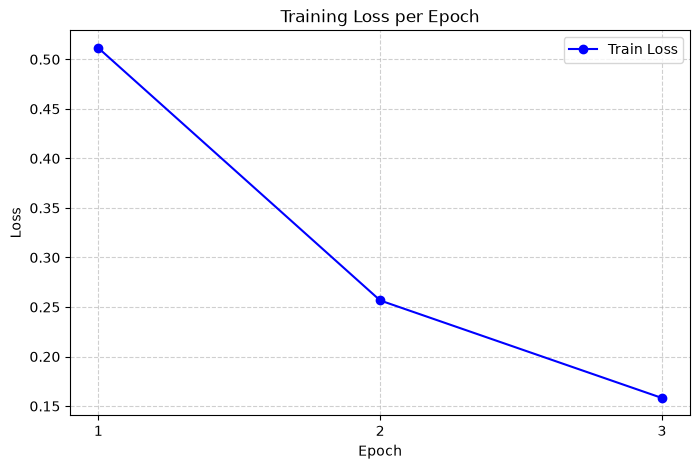

In [60]:
# visualize the training loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), epoch_losses, marker='o', color='b', label='Train Loss')
plt.title('Training Loss per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.xticks(range(1, epochs + 1))
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

---
## 6  Part C — Fine-tuned BERT: Extract & Visualise Representations

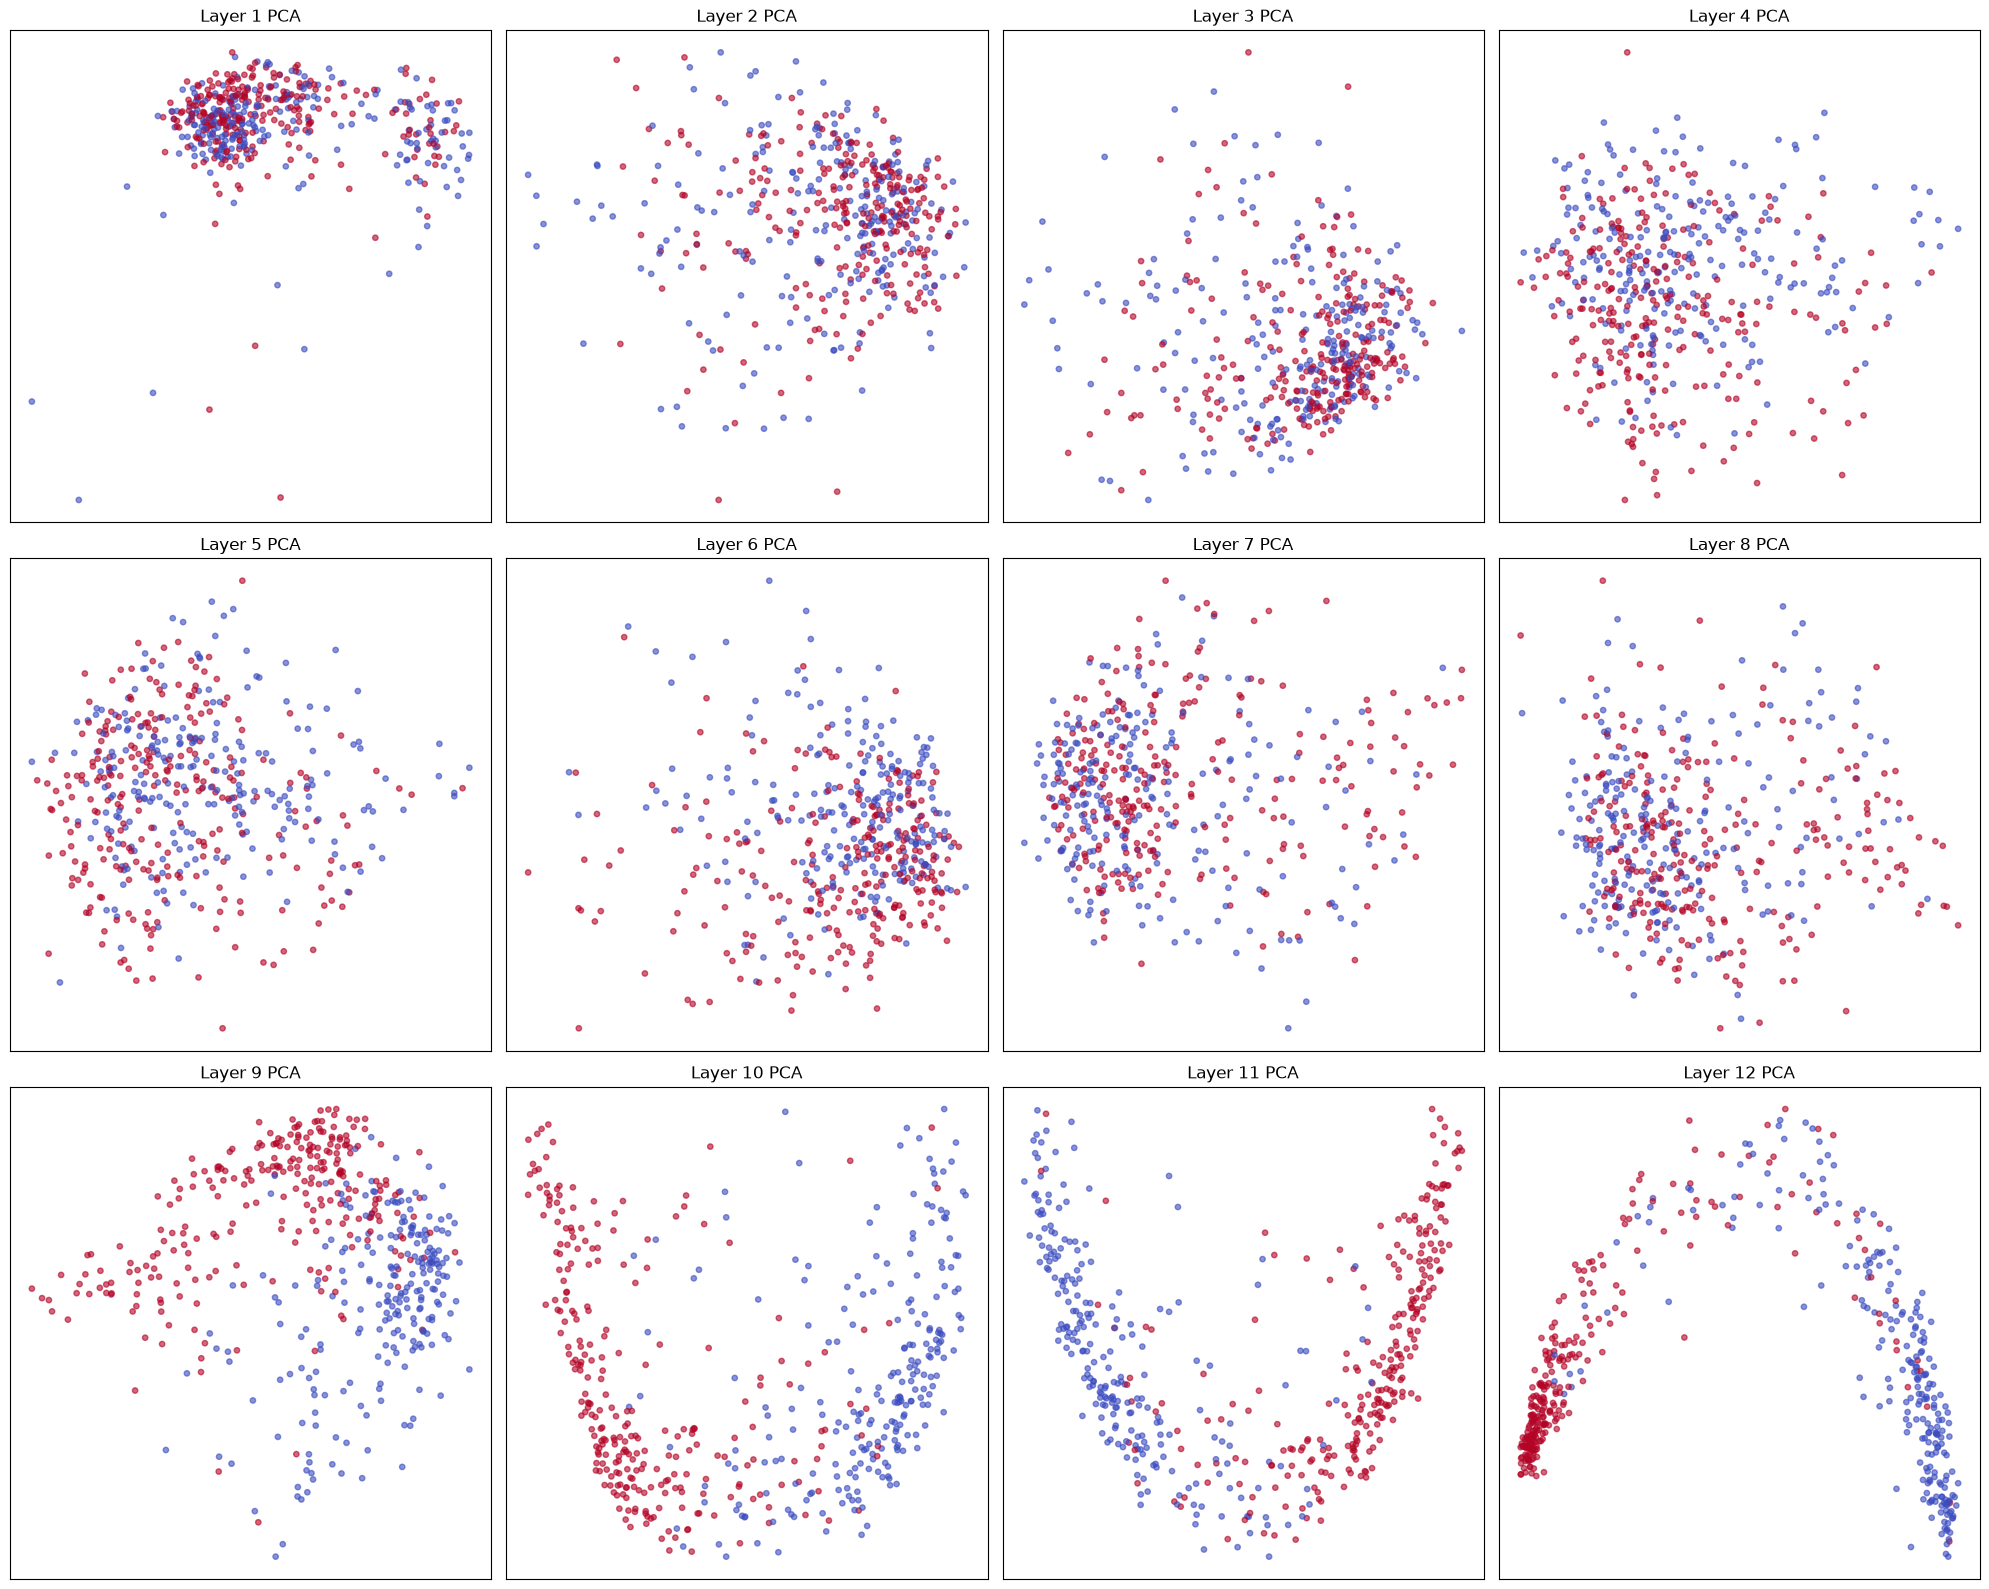

In [61]:
finetuned_cls_repr, val_labels_ft = extract_cls_representations(model, val_dataloader, device)

pca_layers = list(range(1, 13))

fig, axes = plt.subplots(3, 4, figsize=(20, 16))
axes = axes.flatten()

for idx, layer in enumerate(pca_layers):
    pca = PCA(n_components=2)
    
    X = finetuned_cls_repr[layer].numpy()
    y = val_labels_ft.numpy()
    
    X_pca = pca.fit_transform(X)
    
    ax = axes[idx]
    scatter = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='coolwarm', alpha=0.6, s=15)
    ax.set_title(f'Layer {layer} PCA')
    ax.set_xticks([])
    ax.set_yticks([])

for i in range(len(pca_layers), len(axes)):
    axes[i].axis('off')

plt.tight_layout()
plt.show()


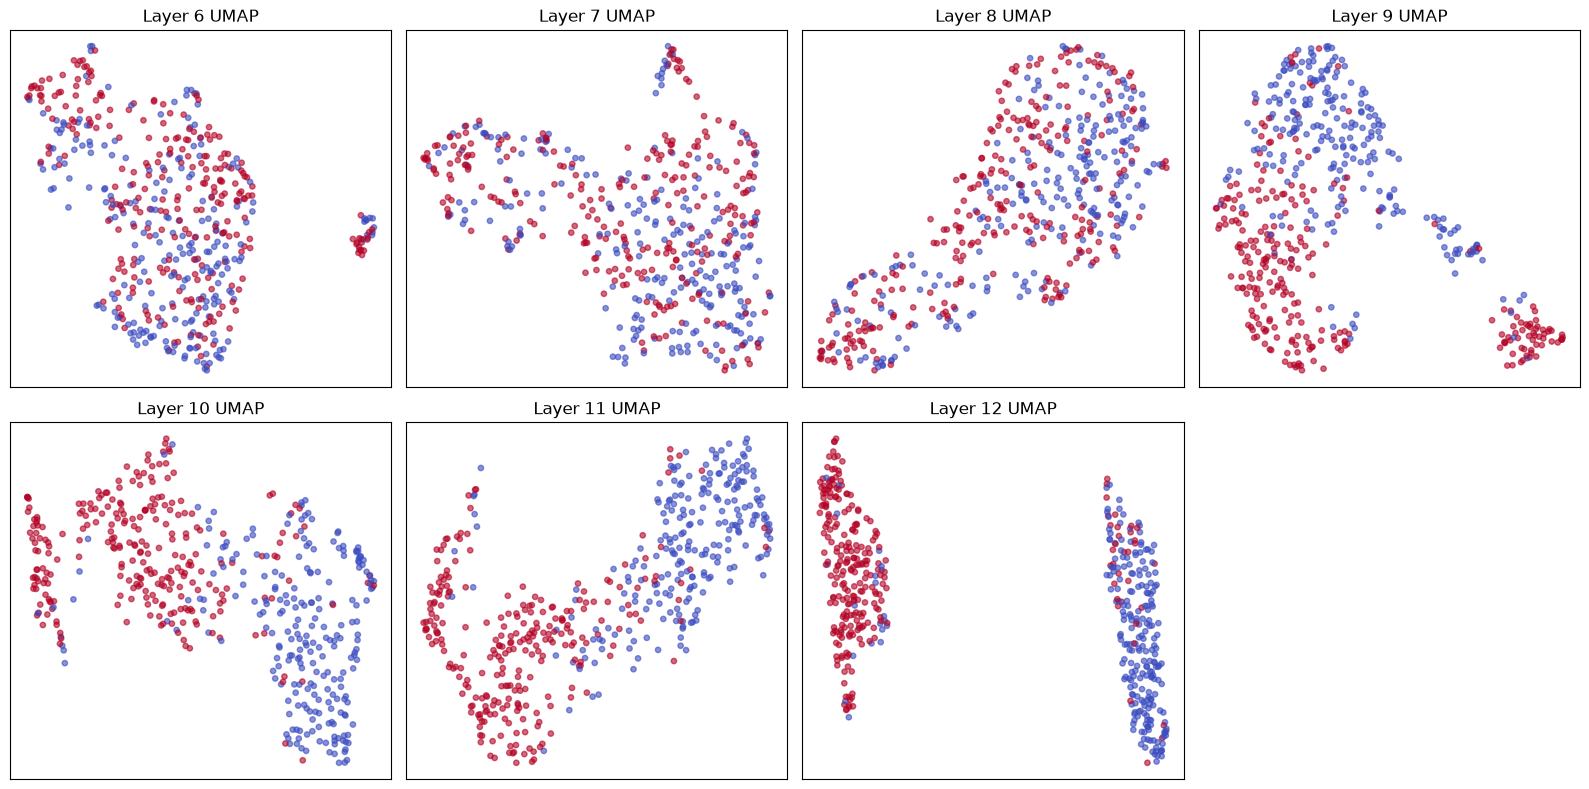

In [62]:
umap_layers = list(range(6, 13)) 

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for idx, layer in enumerate(umap_layers):
    reducer = umap.UMAP(n_components=2, random_state=42)
    
    X = finetuned_cls_repr[layer].numpy()
    y = val_labels_ft.numpy()
    
    X_umap = reducer.fit_transform(X)
    
    ax = axes[idx]
    ax.scatter(X_umap[:, 0], X_umap[:, 1], c=y, cmap='coolwarm', alpha=0.6, s=15)
    ax.set_title(f'Layer {layer} UMAP')
    ax.set_xticks([])
    ax.set_yticks([])

axes[-1].axis('off')

plt.tight_layout()
plt.show()


---
## 7  Part D — Direct Comparison: Before vs After

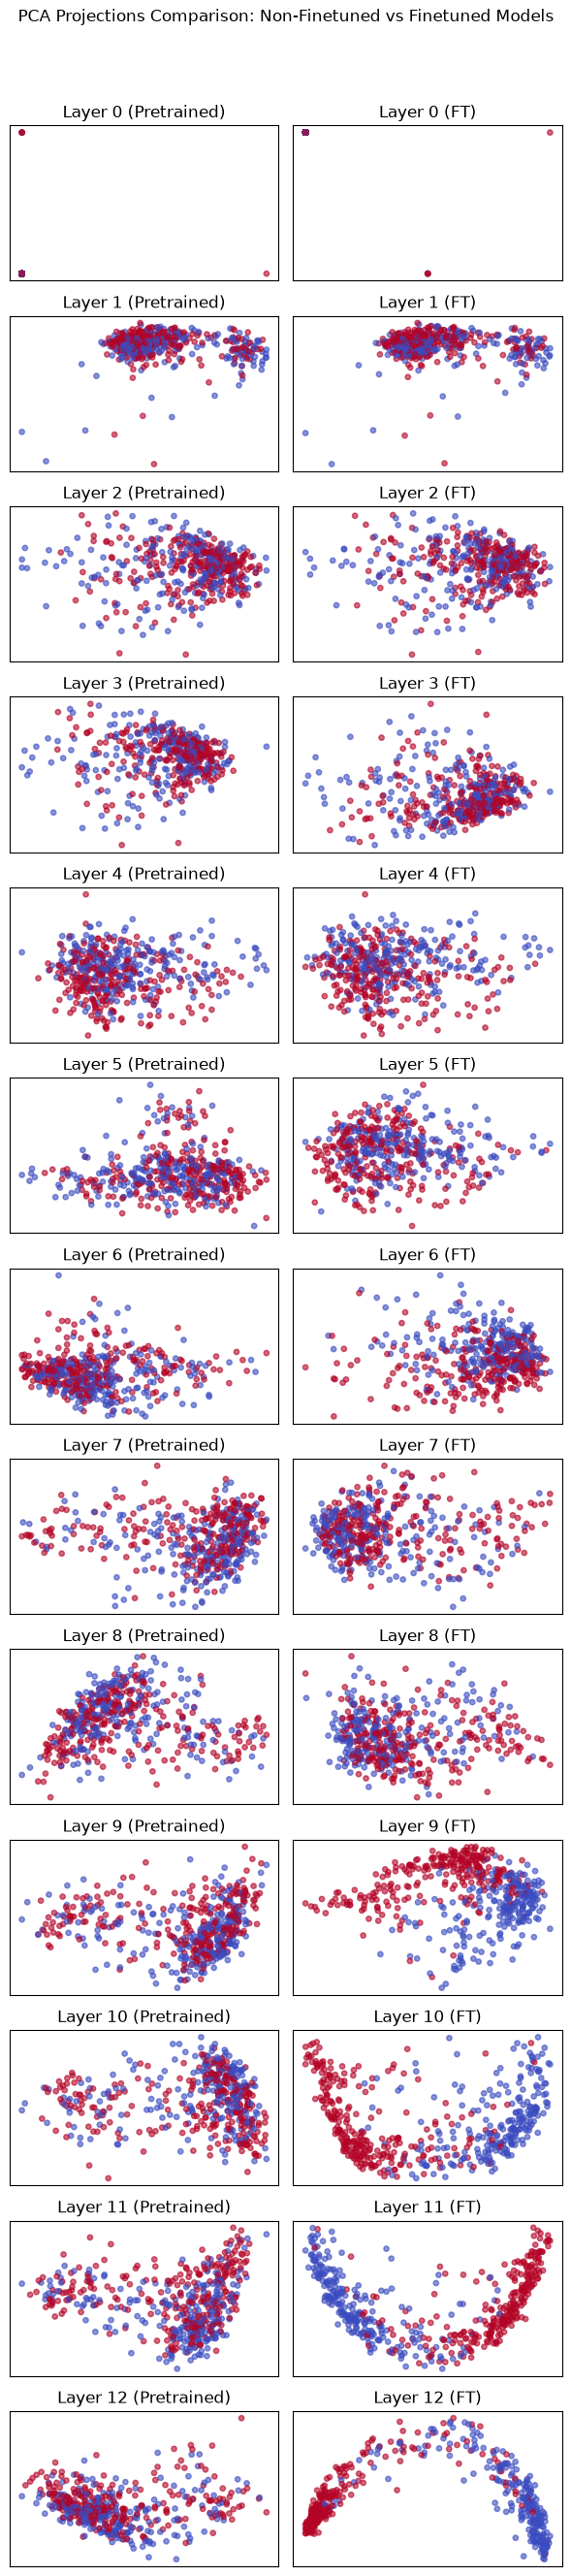

In [84]:
# Helper function to plot PCA or UMAP projections side-by-side for pretrained vs fine-tuned representations
def plot_side_by_side_comparison(val_cls_repr, finetuned_cls_repr, val_labels, val_labels_ft, layers=list(range(6, 13)), method='umap'):
    
    if method not in ['umap', 'pca']:
        raise ValueError("Method must be either 'umap' or 'pca'")

    num_rows = len(layers)

    fig, axes = plt.subplots(num_rows, 2, figsize=(6, 2*num_rows))

    y_non_ft = val_labels
    y_ft = val_labels_ft.numpy()

    for idx, layer in enumerate(layers):
        X_non_ft = val_cls_repr[layer].numpy()

        if method == 'umap':
            reducer = umap.UMAP(n_components=2, random_state=42)
            X_transformed = reducer.fit_transform(X_non_ft)
        else:
            reducer = PCA(n_components=2, random_state=42)
            X_transformed = reducer.fit_transform(X_non_ft)

        ax_non_ft = axes[idx, 0] if num_rows > 1 else axes[0]
        scatter_non_ft = ax_non_ft.scatter(X_transformed[:, 0], X_transformed[:, 1],
                                         c=y_non_ft, cmap='coolwarm', alpha=0.6, s=15)
        ax_non_ft.set_title(f'Layer {layer} (Pretrained)')
        ax_non_ft.set_xticks([])
        ax_non_ft.set_yticks([])

        X_ft = finetuned_cls_repr[layer].numpy()

        if method == 'umap':
            reducer = umap.UMAP(n_components=2, random_state=42)
            X_transformed = reducer.fit_transform(X_ft)
        else:
            reducer = PCA(n_components=2, random_state=42)
            X_transformed = reducer.fit_transform(X_ft)

        ax_ft = axes[idx, 1] if num_rows > 1 else axes[1]
        scatter_ft = ax_ft.scatter(X_transformed[:, 0], X_transformed[:, 1],
                                   c=y_ft, cmap='coolwarm', alpha=0.6, s=15)
        ax_ft.set_title(f'Layer {layer} (FT)')
        ax_ft.set_xticks([])
        ax_ft.set_yticks([])

    method_name = method.upper()
    fig.suptitle(f'{method_name} Projections Comparison: Non-Finetuned vs Finetuned Models', y=1.02)

    plt.tight_layout()
    plt.show()
plot_side_by_side_comparison(val_cls_repr, finetuned_cls_repr, val_labels, val_labels_ft, method='pca', layers=list(range(0, 13)))

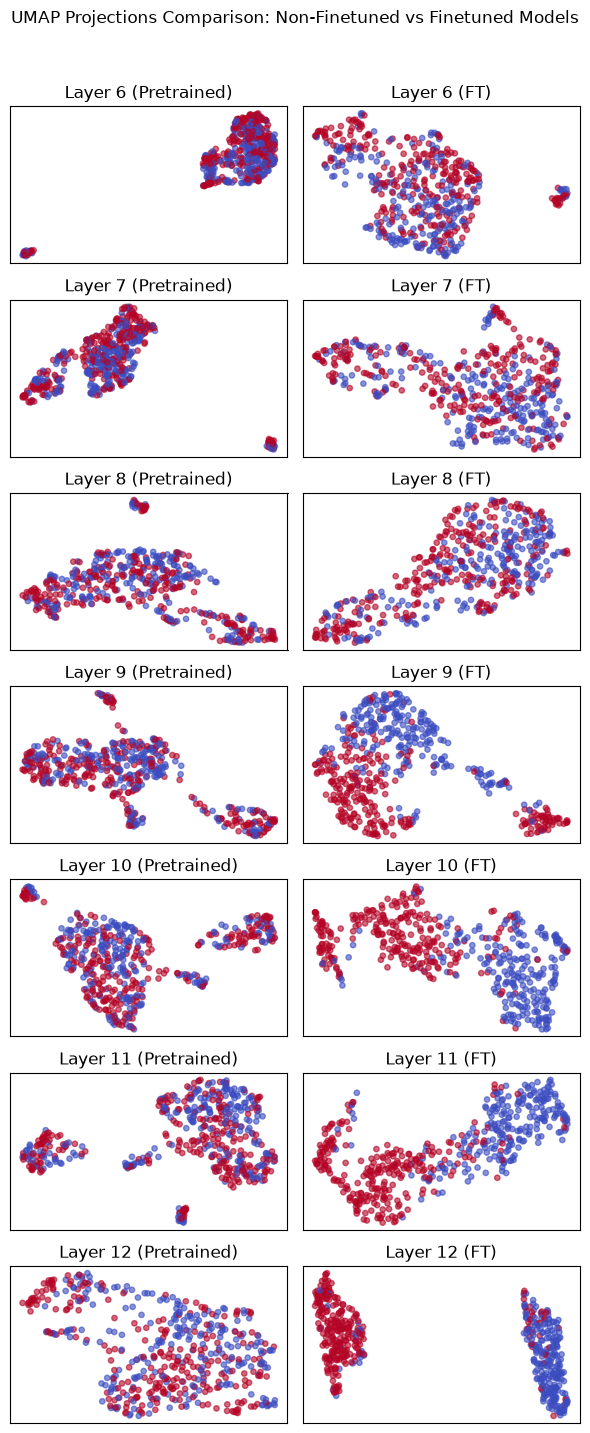

In [85]:
plot_side_by_side_comparison(val_cls_repr, finetuned_cls_repr, val_labels, val_labels_ft, method='umap')

### 7.1  Probe accuracy comparison

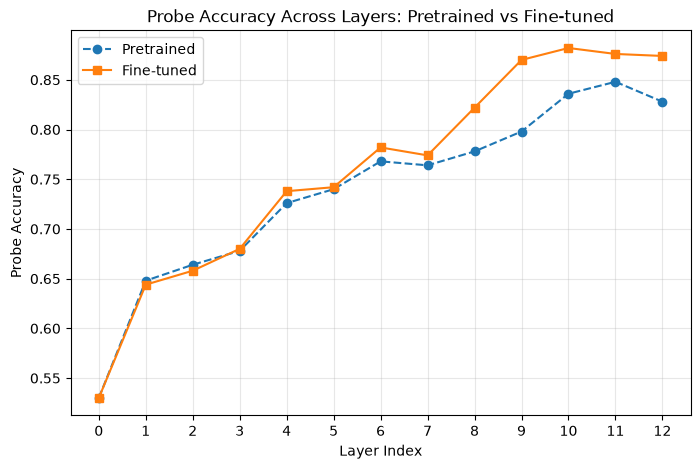

In [ ]:
# visualize probe scores before and after fine-tuning

finetuned_probe_accs = []
num_layers = 12

for layer_idx in range(num_layers + 1):
    X = finetuned_cls_repr[layer_idx].cpu().numpy()
    y = val_labels_ft.cpu().numpy()
    
    clf = LogisticRegression(max_iter=1000, random_state=42)
    
    scores = cross_val_score(clf, X, y, cv=5)
    finetuned_probe_accs.append(scores.mean())

pretrained_accs = [probe_scores[i] for i in range(num_layers + 1)]

plt.figure(figsize=(8, 5))
plt.plot(range(num_layers + 1), pretrained_accs, label='Pretrained', marker='o', linestyle='--')
plt.plot(range(num_layers + 1), finetuned_probe_accs, label='Fine-tuned', marker='s')

plt.xlabel("Layer Index")
plt.ylabel("Probe Accuracy")
plt.title("Probe Accuracy Across Layers: Pretrained vs Fine-tuned")
plt.xticks(range(num_layers + 1))
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

> **💬 Question 2 (written answer):**  
> Compare the probe accuracy curves before and after fine-tuning.  
> a) Which layers changed the most?  
> b) Why do you think those specific layers changed while others did not?  
<div dir="rtl" style="text-align: right; line-height: 2; font-family: Vazir, Tahoma, sans-serif;">
 الف) همانطور که در نمودار مشخص است، بیشترین تغییرات از لایه هشتم به  بعد اتفاق افتاده است. بیشترین فاصله دقت مربوط به لایه نهم و بهترین دقت فاین تیون شده مربوط به لایه دهم است.
 </div>
<div dir="rtl" style="text-align: right; line-height: 2; font-family: Vazir, Tahoma, sans-serif;">
 ب) به خاطر این که لایه های پایین تر ویژگی های عمومی زبان مثل شکل کلمات، علائم نگارشی را یاد گرفته اند. همچنین لایه های میانی اطلاعات نحوی مثل گرامر، نقش کلمه در جمله را یاد گرفته اند. از آنجایی که تسک نهایی همچنان به این موارد وابسته است، این بازنمایی های اولیه در فاین تیون خیلی تغییری نمی‌کنند. اما لایه های بالاتر به هد کلسیفیکیشن نزدیک تر هستند و برای درک مفهوم و تسک نهایی هستند، بیشتر تغییر می‌کنند تا بازنمایی آن ها مناسب برای تسک هدف شوند.
  </div>

### 7.2  Inter-layer cosine similarity heatmap
How similar are representations across layers? Does fine-tuning change layer similarity?

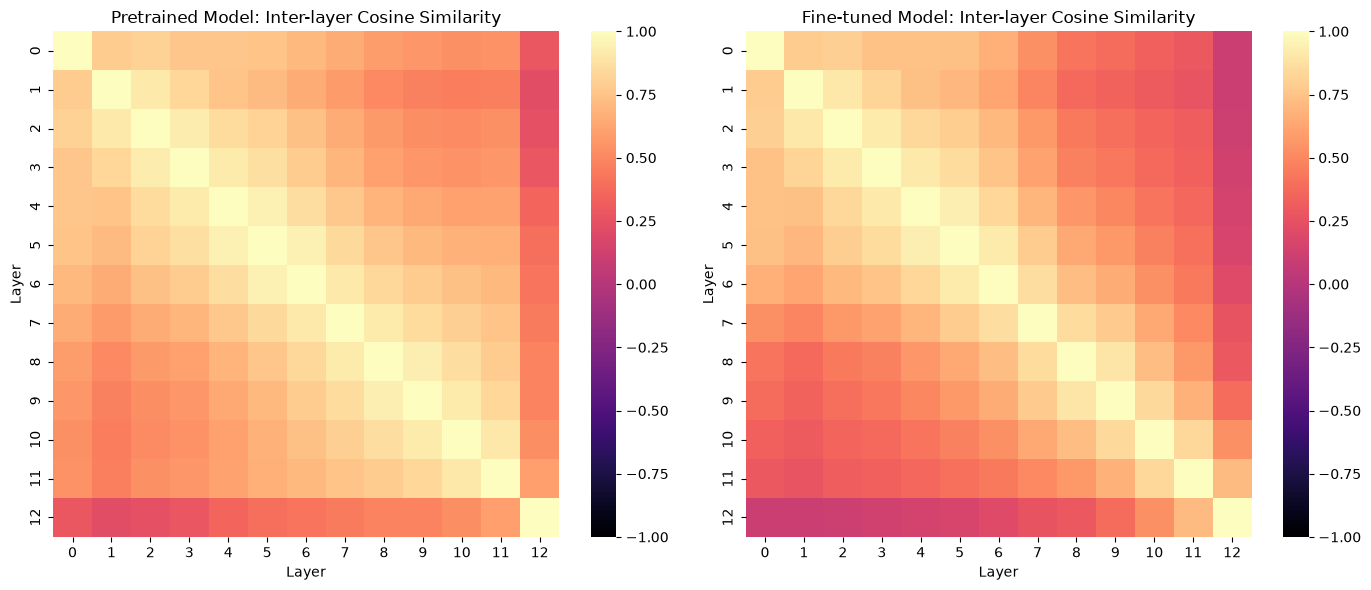

In [ ]:
# Inter-layer similarity analysis: compute the average cosine similarity between the mean [CLS] vectors of every layer pair, before and after fine-tuning, and visualize as heatmaps

def compute_interlayer_cosine_similarity(cls_repr_dict):
    layer_ids = sorted(cls_repr_dict.keys())
    num_layers = len(layer_ids)
    sim_matrix = torch.zeros(num_layers, num_layers)

    normalized = {
        i: F.normalize(cls_repr_dict[i], p=2, dim=1)
        for i in layer_ids
    }

    for a, i in enumerate(layer_ids):
        for b, j in enumerate(layer_ids):
            cos_sim = (normalized[i] * normalized[j]).sum(dim=1)
            sim_matrix[a, b] = cos_sim.mean()

    return sim_matrix.cpu().numpy(), layer_ids

pretrained_sim_matrix, layer_ids = compute_interlayer_cosine_similarity(val_cls_repr)
finetuned_sim_matrix, _ = compute_interlayer_cosine_similarity(finetuned_cls_repr)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.heatmap(pretrained_sim_matrix, ax=axes[0], cmap='magma', vmin=-1, vmax=1, xticklabels=layer_ids, yticklabels=layer_ids)
axes[0].set_title('Pretrained Model: Inter-layer Cosine Similarity')
axes[0].set_xlabel('Layer')
axes[0].set_ylabel('Layer')

sns.heatmap(finetuned_sim_matrix, ax=axes[1], cmap='magma', vmin=-1, vmax=1, xticklabels=layer_ids, yticklabels=layer_ids)
axes[1].set_title('Fine-tuned Model: Inter-layer Cosine Similarity')
axes[1].set_xlabel('Layer')
axes[1].set_ylabel('Layer')

plt.tight_layout()
plt.show()


> **💬 Question 3 (written answer):**  
> Looking at the inter-layer similarity heatmaps, describe how the layer structure changes after fine-tuning.  
> Are the deep layers more or less similar to each other compared to the pretrained model?

<div dir="rtl" style="text-align: right; line-height: 2; font-family: Vazir, Tahoma, sans-serif;">
با توجه به هیتمپ ها، در مدل از پیش آموزش دیده، شباهت ها کمی پخش هستند و چندین لایه مجاور مقادیر شباهت بالایی دارند که یعنی بازنمایی ها از یک لایه به لایه دیگر تغییر شدیدی نمی‌کند. اما پس از فاین تیون کردن مدل، نواحی دارای شباهت بالا به شکل متراکم تری در قطر اصلی قرار گرفته اند که یعنی بازنمایی ها در هر لایه متمایز تر هستند.
</div>
<div dir="rtl" style="text-align: right; line-height: 2; font-family: Vazir, Tahoma, sans-serif;">
لایه های عمیق در مدل فاین تیون شده شباهت کمتری با هم دارند و رنگ ها اطراف قطر اصلی کمی تیره تر شده اند. همچنین لایه دوازدهم پس از فاین تیون ایزوله تر از قبل شده است که یعنی بازنمایی آن برای این تسک تخصصی تر شده است. به طور کلی فاین تیون باعث شده لایه های عمیق با تسک بهتر سازگار شوند.
</div>

---
## 8  Final Evaluation

In [ ]:
# Final evaluation of the fine-tuned model on the validation set

model.eval()

total_eval_accuracy = 0
total_eval_loss = 0
nb_eval_steps = 0

for batch in val_dataloader:
    b_input_ids = batch[0].to(device)
    b_input_mask = batch[1].to(device)
    b_labels = batch[2].to(device)
    
    with torch.no_grad():        
        outputs = model(b_input_ids,  token_type_ids=None, attention_mask=b_input_mask, labels=b_labels)
        
    loss = outputs.loss
    logits = outputs.logits
    
    total_eval_loss += loss.item()
    
    logits = logits.detach().cpu().numpy()
    label_ids = b_labels.to('cpu').numpy()
    
    preds = np.argmax(logits, axis=1).flatten()
    labels = label_ids.flatten()
    total_eval_accuracy += np.sum(preds == labels) / len(labels)
    
    nb_eval_steps += 1

avg_val_accuracy = total_eval_accuracy / nb_eval_steps
avg_val_loss = total_eval_loss / nb_eval_steps

print(f"Validation Loss: {avg_val_loss:.4f}")
print(f"Validation Accuracy: {avg_val_accuracy:.4f}")


Validation Loss: 0.2903
Validation Accuracy: 0.8902


---
## 9  Summary & Reflection

> **💬 Question 4 (written answer — ~200 words):**  
> Summarise what you observed across all four parts.  
> - What did the PCA / UMAP visualisations show about how representations change?  
> - What does the probe accuracy tell us about where sentiment is encoded?  
> - What is one limitation of the visualisation approach we used (e.g. PCA projection)?  

<div dir="rtl" style="text-align: right; line-height: 2; font-family: Vazir, Tahoma, sans-serif;">
طبق نمایش با PCA و UMAP ، در مدل از پیش آموزش دیده بازنمایی کلاس ها در  هم تنیده است. اما بعد از فاین تیون با حرکت به سمت لایه های عمیق تر، کلاس ها به شکل بهتری از هم جدا می‌شوند.
</div>
<div dir="rtl" style="text-align: right; line-height: 2; font-family: Vazir, Tahoma, sans-serif;">
نمودار probe accuracy هم همین طور است. دقت در لایه 0 تقریبا تصادفی است و با حرکت به سمت لایه های بعد، بالا می‌رود که یعنی ویژگی  های مربوط به احساسات به تدریج در طول شبکه ساخته می‌شوند و در یک لایه متمرکز نیستند. همچنین فاین تیون کردن جدایی پذیری خطی را در لایه های آخر افزایش داده است

</div>
<div dir="rtl" style="text-align: right; line-height: 2; font-family: Vazir, Tahoma, sans-serif;">
 یکی از محدودیت های اصلی روش‌ PCA، از دست رفتن اطلاعات است. با کاهش فضای ۷۶۸ بعدی به ۲ بعد، PCA فقط جهت های دارای بیشترین واریانس را حفظ می‌کند. در نتیجه، کلاس هایی که ممکن است در فضای چند بعدی کاملا تفکیک پذیر باشند، ممکن است در نمودار دو بعدی به صورت کاذب در هم تنیده به نظر برسند.
 </div>
<div dir="rtl" style="text-align: right; line-height: 2; font-family: Vazir, Tahoma, sans-serif;">
مشکل اصلی روش UMAP این است که اگر چه ساختار های  Local را به خوبی حفظ می‌کند، اما ممکن است فواصل و ساختار های Global داده ها را دچار اعوجاج کند، یعنی فاصله بین خوشه های مختلف در فضای 2
 بعدی لزوما نشان دهنده فاصله واقعی آن ها در فضای اصلی نیست. همچنین، شکل نهایی خروجی به شدت به تنظیمات هایپر پارامتر ها وابسته است و تغییر آن ها می‌تواند شکل خوشه ها را عوض کرده و منجر به تفسی های گمراه کننده شود. 
</div>